<a href="https://colab.research.google.com/github/Anthea05/Anthea_machine-learning/blob/main/JS08/JS08Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import hdbscan
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

In [2]:
iris = load_iris()
X = iris.data

Jumlah cluster terbentuk: 2
Banyaknya noise: 0


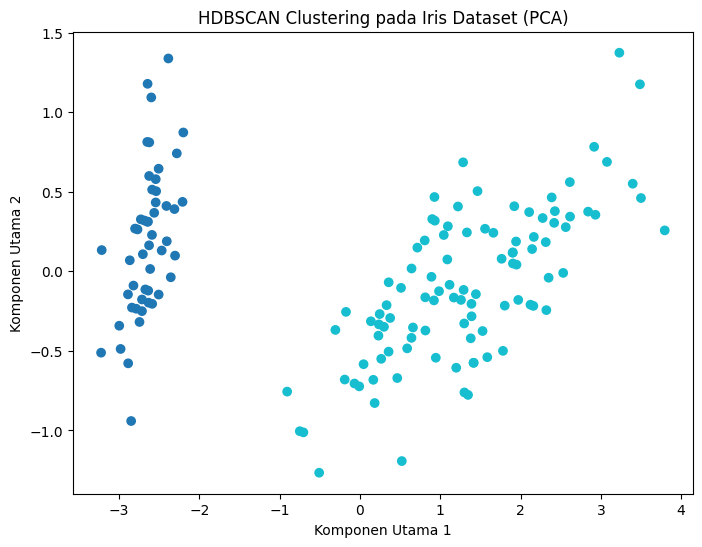

In [3]:
hdb = hdbscan.HDBSCAN(min_cluster_size=10, min_samples=5)
labels = hdb.fit_predict(X)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print(f"Jumlah cluster terbentuk: {n_clusters}")
print(f"Banyaknya noise: {n_noise}")

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10')
plt.title('HDBSCAN Clustering pada Iris Dataset (PCA)')
plt.xlabel('Komponen Utama 1')
plt.ylabel('Komponen Utama 2')
plt.show()

**Analisis Singkat Clustering Iris dengan HDBSCAN:**
Hasil clustering menggunakan HDBSCAN umumnya hanya mengidentifikasi dua cluster utama, bukan tiga seperti yang ditunjukkan oleh label asli dari scikit-learn (Setosa, Versicolor, Virginica). Fenomena ini terjadi karena spesies Iris setosa terisolasi dengan cukup jauh sehingga dengan mudah dikenali sebagai satu cluster yang terpisah oleh HDBSCAN. Di sisi lain, spesies Iris versicolor dan Iris virginica memiliki fitur yang saling beririsan dan tumpang tindih. Karena HDBSCAN mengelompokkan data sepenuhnya berdasarkan tingkat kepadatan (density), algoritma ini menganggap tumpang tindih tersebut sebagai satu area padat yang sama dan menggabungkannya menjadi satu cluster besar, sambil menandai titik-titik yang terpisah di batas luarnya sebagai noise (label -1). Sebagai kesimpulan, jumlah cluster yang terdeteksi tidak sama dengan label asli, tetapi dalam hal topologi kepadatan spasial, algoritma ini telah berhasil memetakan struktur asli dari data tersebut.